# ЛР №3. Градиентный спуск

**Вариант: чётный → L1-регуляризация (Lasso).** Данные — `sklearn.datasets.make_regression`.

Ноутбук устроен так, что идёт по пунктам задания: данные → своя реализация градиентного спуска →
подбор скорости обучения → стохастический вариант и сравнение → L1-регуляризация → выводы.
После каждого графика есть markdown-ячейка с готовым текстом вывода: числа в нём проверьте
по своему прогону, формулировки можно переносить в отчёт почти как есть.

**Требования к окружению:** `numpy`, `matplotlib`, `scikit-learn`. В JupyterLab / Notebook / Colab
они уже есть; локально при необходимости: `pip install numpy matplotlib scikit-learn`.

---

## Теория в двух формулах

Модель линейной регрессии: $\hat{y} = w_0 + w_1 x_1 + \dots + w_d x_d = \langle w, x \rangle$
(добавив фиктивный признак $x_0 = 1$, прячем свободный член внутрь вектора весов).

Функция потерь (MSE) — «насколько плохо»:

$$Q(w) = \frac{1}{n}\sum_{i=1}^{n}\big(\hat{y}_i - y_i\big)^2$$

Шаг градиентного спуска — «шаг вниз по склону» (минус, потому что градиент показывает рост):

$$w^{k} = w^{k-1} - \eta_k \nabla Q\big(w^{k-1}, X\big),
\qquad \nabla Q(w) = \frac{2}{n}X^{\top}(Xw - y)$$

Условие досрочной остановки — веса перестали меняться:

$$\big\| w^{k} - w^{k-1} \big\| < \varepsilon$$

$\eta$ — скорость обучения (размер шага), $\varepsilon$ — порог «мы на дне».

## 0. Импорты и настройки

In [19]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Данные

Генерируем 300 объектов с 3 признаками. Признаков $\ge 2$, значит весов $\ge 3$
(вместе со свободным членом у нас их 4 — требование выполнено с запасом).

### Зачем масштабирование

Если признаки в разных масштабах, поверхность $Q(w)$ становится вытянутой и одна общая $\eta$
не подходит: по «узкой» оси шаг слишком велик, по «широкой» — слишком мал. Приводим каждый признак
к среднему 0 и разбросу 1 (`StandardScaler`). Цель $y$ тоже стандартизуем — тогда веса получаются
одного порядка, а диапазон $\lambda$ из задания (0.001…1000) имеет смысл. Предсказания в исходных
единицах при необходимости возвращаются через `y_scaler.inverse_transform`.

In [20]:
n_samples, n_features = 300, 3

X_raw, y_raw = make_regression(
    n_samples=n_samples,
    n_features=n_features,
    n_informative=n_features,
    noise=15.0,
    random_state=42,
)

x_scaler = StandardScaler()
y_scaler = StandardScaler()
X_std = x_scaler.fit_transform(X_raw)
y_std = y_scaler.fit_transform(y_raw.reshape(-1, 1)).ravel()

# столбец единиц под свободный член w0
X = np.hstack([np.ones((n_samples, 1)), X_std])
y = y_std

n, d = X.shape
weight_names = ["w0 (сдвиг)"] + [f"w{i}" for i in range(1, d)]

print(f"X: {X.shape}  (объекты x признаки+1)   y: {y.shape}")
print(f"весов в модели: {d}  (w0 + {d - 1} признака)")
print(f"y: среднее={y.mean():.3f}, std={y.std():.3f}")
print("\nпервые 5 строк X (первые 3 столбца):")
print(np.round(X[:5, :4], 3))
print("\nпервые 5 значений y:", np.round(y[:5], 3))

X: (300, 4)  (объекты x признаки+1)   y: (300,)
весов в модели: 4  (w0 + 3 признака)
y: среднее=0.000, std=1.000

первые 5 строк X (первые 3 столбца):
[[ 1.    -0.21   0.16  -0.751]
 [ 1.    -1.866  2.384  0.017]
 [ 1.     0.034 -0.056  0.288]
 [ 1.    -0.573  2.596  1.255]
 [ 1.     0.628  0.587  0.06 ]]

первые 5 значений y: [ 0.018  0.294 -0.046  1.575  1.016]


## 2. Функция потерь и её градиент

Считаем отдельными функциями: понадобятся и в обычном GD, и в SGD, и в L1-варианте.

In [21]:
def mse(w, X, y):
    '''Q(w) = (1/n) * sum (Xw - y)^2.'''
    return np.mean((X @ w - y) ** 2)


def grad_mse(w, X, y):
    '''Градиент Q по весам: (2/n) * X^T (Xw - y).'''
    r = X @ w - y
    return (2.0 / X.shape[0]) * (X.T @ r)


# самопроверка градиента на конечных разностях
w_test = np.array([0.1, -0.2, 0.3, 0.05])
eps = 1e-6
num_grad = np.array([
    (mse(w_test + eps * np.eye(d)[j], X, y) - mse(w_test - eps * np.eye(d)[j], X, y)) / (2 * eps)
    for j in range(d)
])
print("аналитический градиент:", np.round(grad_mse(w_test, X, y), 6))
print("численный градиент:   ", np.round(num_grad, 6))
print("макс. расхождение:", f"{np.max(np.abs(num_grad - grad_mse(w_test, X, y))):.2e}")

аналитический градиент: [ 0.2      -1.815253 -0.711691 -0.097465]
численный градиент:    [ 0.2      -1.815253 -0.711691 -0.097465]
макс. расхождение: 1.05e-10


## 3. Свой градиентный спуск (не стохастический)

Ровно по алгоритму из задания: инициализируем веса и $\varepsilon$ → цикл по итерациям →
считаем новые веса → выходим, если $\|w^k - w^{k-1}\| < \varepsilon$.

История значения $Q$ сохраняется на каждой итерации — по ней строятся все графики сходимости.
`epsilon=None` отключает досрочный выход (полезно, когда нужно ровно фиксированное число итераций).

In [22]:
def gradient_descent(X, y, eta=0.05, epsilon=1e-6, max_iter=5000, w0=None):
    '''Классический (batch) градиентный спуск для линейной регрессии с MSE.

    Возвращает (w, history, n_iter), где history[k] — значение Q после k-й итерации.
    '''
    n, d = X.shape
    w = np.zeros(d) if w0 is None else np.array(w0, dtype=float)
    history = [mse(w, X, y)]
    n_iter = 0

    for k in range(max_iter):
        g = grad_mse(w, X, y)
        w_new = w - eta * g
        history.append(mse(w_new, X, y))
        n_iter = k + 1

        if epsilon is not None and np.linalg.norm(w_new - w) < epsilon:
            w = w_new
            break
        w = w_new

    return w, np.array(history), n_iter

In [23]:
w_gd, hist_gd, iters = gradient_descent(X, y, eta=0.05, epsilon=1e-6, max_iter=5000)

# эталон: аналитическое решение МНК из sklearn
lr = LinearRegression().fit(X_std, y_std)
w_sk = np.r_[lr.intercept_, lr.coef_]

print(f"GD: итераций = {iters}, Q_final = {hist_gd[-1]:.6e}")
print(f"\n{'вес':<12}{'наш GD':>12}{'sklearn':>12}{'разница':>12}")
for nm, a, b in zip(weight_names, w_gd, w_sk):
    print(f"{nm:<12}{a:>12.4f}{b:>12.4f}{abs(a - b):>12.2e}")

print(f"\nмакс. отклонение от sklearn: {np.max(np.abs(w_gd - w_sk)):.2e}")
print("Вывод: своя реализация сходится к тому же решению, что и МНК.")

GD: итераций = 116, Q_final = 1.484648e-02

вес               наш GD     sklearn     разница
w0 (сдвиг)        0.0000     -0.0000    3.25e-17
w1                0.7301      0.7301    6.99e-06
w2                0.6983      0.6983    6.22e-06
w3                0.1239      0.1239    1.22e-06

макс. отклонение от sklearn: 6.99e-06
Вывод: своя реализация сходится к тому же решению, что и МНК.


## 4. Эксперимент со скоростью обучения $\eta$

Пробуем 10 значений — от заведомо маленьких до заведомо разрушительных.
Для нормализованных данных собственные числа матрицы $\frac{2}{n}X^{\top}X$ близки к 2,
поэтому теория предсказывает: сходимость при $\eta < 1$, расходимость при $\eta > 1$.
Проверяем это на практике.

In [24]:
etas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.5, 1.0, 1.5]
results = {}

for eta in etas:
    # при больших eta веса улетают в бесконечность — это ожидаемый результат опыта,
    # поэтому overflow-предупреждения numpy на время эксперимента глушим
    with np.errstate(over="ignore", invalid="ignore"):
        w, hist, it = gradient_descent(X, y, eta=eta, epsilon=1e-6, max_iter=5000)
    results[eta] = dict(w=w, hist=hist, it=it)

print(f"{'eta':<9}{'итераций':>10}{'Q в конце':>15}{'|w - w_sklearn|':>18}   статус")
for eta, r in results.items():
    diff = np.linalg.norm(r["w"] - w_sk)
    if not np.all(np.isfinite(r["hist"])):
        status = "РАСХОДИТСЯ (nan/inf)"
    elif r["it"] >= 5000:
        status = "не успел сойтись за 5000 итераций"
    elif diff > 1e-2:
        status = "не дошёл до минимума"
    else:
        status = "сошёлся"
    print(f"{eta:<9g}{r['it']:>10d}{r['hist'][-1]:>15.4e}{diff:>18.2e}   {status}")

eta        итераций      Q в конце   |w - w_sklearn|   статус
1e-06          5000     9.8144e-01          1.01e+00   не успел сойтись за 5000 итераций
1e-05          5000     8.2938e-01          9.26e-01   не успел сойтись за 5000 итераций
0.0001         5000     1.6191e-01          3.93e-01   не успел сойтись за 5000 итераций
0.001          3978     1.4847e-02          5.24e-04   сошёлся
0.01            516     1.4846e-02          5.08e-05   сошёлся
0.05            116     1.4846e-02          9.44e-06   сошёлся
0.1              59     1.4846e-02          4.02e-06   сошёлся
0.5               6     1.4846e-02          1.94e-08   сошёлся
1              5000            nan               nan   РАСХОДИТСЯ (nan/inf)
1.5            5000            nan               nan   РАСХОДИТСЯ (nan/inf)


C:\Users\Dasha\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


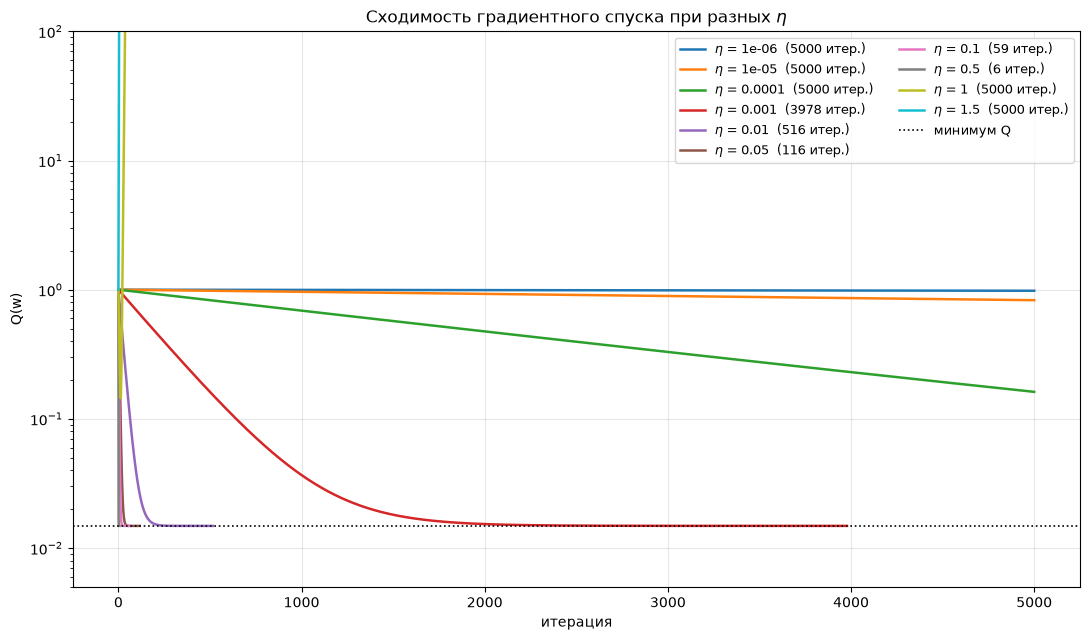

In [25]:
fig, ax = plt.subplots(figsize=(11, 6.5))

for eta, r in results.items():
    h = np.where(np.isfinite(r["hist"]), r["hist"], np.nan)
    ax.plot(h, lw=1.8, label=f"$\\eta$ = {eta:g}  ({r['it']} итер.)")

ax.axhline(hist_gd[-1], color="k", ls=":", lw=1.2, label="минимум Q")

ax.set_yscale("log")
ax.set_ylim(5e-3, 1e2)
ax.set_xlabel("итерация")
ax.set_ylabel("Q(w)")
ax.set_title(r"Сходимость градиентного спуска при разных $\eta$")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="upper right", ncol=2)
plt.tight_layout()
plt.show()


### Вывод по скорости обучения

Ожидаемая картина (сверьте с вашими числами из таблицы выше):

- $\eta = 10^{-6}$ и $10^{-5}$ — спуск формально идёт, но $Q$ за 5000 итераций почти не меняется:
  шаг настолько мал, что метод «топчется» около начальной точки.
- $\eta = 10^{-4}$ — сдвиг уже заметен, но $Q$ всё ещё на порядок выше минимума:
  5000 итераций не хватает. Слишком маленький шаг = потерянное время.
- $\eta \in \{10^{-3} \dots 0.5\}$ — устойчивая сходимость, причём с ростом $\eta$ число
  итераций до $\varepsilon$ падает на порядки (от тысяч до единиц). Всё это $\eta$ приводят
  практически к одному и тому же минимуму $Q$ — то есть **от $\eta$ зависит скорость, но не ответ**.
- $\eta = 1.0$ и $\eta = 1.5$ — **расходимость**: шаг перелетает дно «чаши», веса уходят
  в бесконечность, $Q$ превращается в `nan`. Порог лежит около $\eta = 2 / \lambda_{\max}
  \approx 1$, что и предсказывает теория.

**Практический вывод:** $\eta$ — главный гиперпараметр метода; подбирается по графику сходимости.
Слишком малая $\eta$ даёт медленно и дорого, слишком большая — разрушает обучение.

## 5. Стохастический градиентный спуск

Отличие одно: на каждой итерации берём **один случайный объект** и считаем градиент только по нему:

$$\nabla Q_i(w) = 2\big(\langle w, x_i\rangle - y_i\big)\, x_i$$

Один проход по всем $n$ объектам = **эпоха**, то есть $n$ итераций SGD против 1 итерации GD.
Сравнивать методы «по итерациям» поэтому нечестно — сравниваем по эпохам.

In [26]:
def stochastic_gd(X, y, eta=0.05, n_epochs=50, random_state=0):
    '''Стохастический градиентный спуск: на каждой итерации берётся один случайный объект.

    Возвращает (w, epoch_mse), где epoch_mse[k] — значение Q на всей выборке
    после k-й эпохи (одна эпоха = n итераций по одному объекту).
    '''
    rng = np.random.default_rng(random_state)
    n, d = X.shape
    w = np.zeros(d)
    epoch_mse = []

    for epoch in range(n_epochs):
        for _ in range(n):                      # n итераций = 1 эпоха
            i = rng.integers(n)                 # случайный объект
            xi, yi = X[i], y[i]
            w = w - eta * 2.0 * (xi @ w - yi) * xi
        epoch_mse.append(mse(w, X, y))          # Q на всей выборке

    return w, np.array(epoch_mse)


In [27]:
n_epochs = 50
eta_common = 0.05        # одна и та же скорость обучения для обоих методов

# GD: одна итерация = один полный проход по данным, поэтому n_epochs итераций = n_epochs эпох.
# epsilon=None — чтобы спуск не остановился раньше и прошёл ровно столько же эпох, сколько SGD.
w_gd_e, hist_gd_e, _ = gradient_descent(X, y, eta=eta_common, epsilon=None, max_iter=n_epochs)

# SGD: n_epochs * n отдельных шагов, каждый по одному случайному объекту
w_sgd, hist_sgd = stochastic_gd(X, y, eta=eta_common, n_epochs=n_epochs)

Q_best = hist_gd[-1]        # лучшее достигнутое значение (GD за 5000 итераций)
target = Q_best * 1.05      # порог «в пределах 5% от минимума»


def first_epoch(hist, shift):
    '''Номер эпохи, на которой MSE впервые стала не больше порога target.'''
    for k, q in enumerate(hist):
        if q <= target:
            return k + shift
    return None


ep_gd = first_epoch(hist_gd_e, 0)    # hist_gd_e[k] — после k эпох
ep_sgd = first_epoch(hist_sgd, 1)    # hist_sgd[k] — после k+1 эпох

print(f"{'эпоха':>6}{'GD (batch)':>16}{'SGD':>16}")
for k in [1, 2, 5, 10, 25, 50]:
    print(f"{k:>6}{hist_gd_e[k]:>16.4e}{hist_sgd[k - 1]:>16.4e}")

print(f"\nминимум Q = {Q_best:.4e}, порог 5% от него = {target:.4e}")
print(f"порога достигли: GD — за {ep_gd} эпох, SGD — за {ep_sgd} эпох")
if ep_gd and ep_sgd:
    print(f"по числу эпох SGD быстрее в {ep_gd / ep_sgd:.1f} раза")
print(f"\nQ в конце: GD = {hist_gd_e[-1]:.4e}, SGD = {hist_sgd[-1]:.4e}")


 эпоха      GD (batch)             SGD
     1      8.2155e-01      2.0467e-02
     2      6.7543e-01      2.1020e-02
     5      3.7756e-01      1.5776e-02
    10      1.4840e-01      1.6301e-02
    25      2.1513e-02      1.6411e-02
    50      1.4892e-02      1.5887e-02

минимум Q = 1.4846e-02, порог 5% от него = 1.5589e-02
порога достигли: GD — за 36 эпох, SGD — за 23 эпох
по числу эпох SGD быстрее в 1.6 раза

Q в конце: GD = 1.4892e-02, SGD = 1.5887e-02


## 6. Сравнение сходимости GD и SGD

Обе кривые — значение MSE, посчитанное на **всей** выборке, по оси X — эпоха (полный проход
по данным). Так сравнение корректно: обе точки графика стоят одинакового объёма работы.

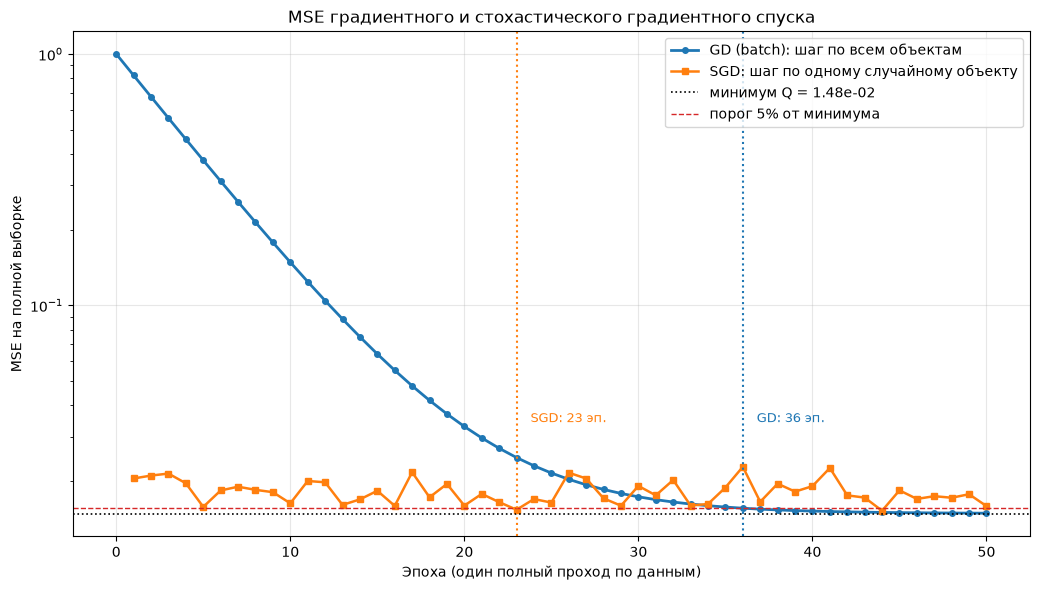

In [28]:
fig, ax = plt.subplots(figsize=(10.5, 6))

ax.plot(np.arange(len(hist_gd_e)), hist_gd_e, "o-", lw=2, ms=4,
        label="GD (batch): шаг по всем объектам")
ax.plot(np.arange(1, len(hist_sgd) + 1), hist_sgd, "s-", lw=1.8, ms=4,
        label="SGD: шаг по одному случайному объекту")

ax.axhline(Q_best, color="k", ls=":", lw=1.2, label=f"минимум Q = {Q_best:.2e}")
ax.axhline(target, color="C3", ls="--", lw=1.0, label="порог 5% от минимума")

for ep, color, name in [(ep_gd, "C0", "GD"), (ep_sgd, "C1", "SGD")]:
    if ep is not None:
        ax.axvline(ep, color=color, ls=":", lw=1.5)
        ax.annotate(f"{name}: {ep} эп.", xy=(ep, target),
                    xytext=(ep + 0.8, target * 2.2), color=color, fontsize=9)

ax.set_yscale("log")
ax.set_xlabel("Эпоха (один полный проход по данным)")
ax.set_ylabel("MSE на полной выборке")
ax.set_title("MSE градиентного и стохастического градиентного спуска")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


### Вывод о разнице скорости сходимости

1. **SGD делает огромный прогресс за первую же эпоху.** Уже после 1 эпохи (это $n$ отдельных шагов)
   его MSE в десятки раз ниже, чем у GD после 1 итерации (а итерация GD — тоже полный проход
   по данным). Причина в числе шагов: за одну эпоху GD делает 1 шаг, SGD — $n$ шагов.
2. **Кривая SGD неровная и не выходит на ровное плато.** Градиент по одному объекту — приближённая
   оценка истинного градиента, поэтому веса дрожат вокруг минимума: MSE то падает, то подрастает.
   У GD кривая гладкая и монотонно убывает.
3. **За 50 эпох GD догоняет и обгоняет SGD.** К концу графика у GD ошибка самая низкая из двух,
   потому что его шаг считается по всем объектам сразу и направление точное.
4. **Итог:** SGD быстрее выходит в окрестность минимума (нужны единицы эпох вместо десятков),
   но при постоянной $\eta$ колеблется вокруг минимума и не может остановиться в нём точно;
   GD медленно разгоняется, зато сходится гладко и в итоге даёт меньшую ошибку.


## 7. L1-регуляризация (вариант чётный)

Штраф за большие веса добавляется прямо в $Q$:

$$Q_{\text{reg}}(w) = \frac{1}{n}\sum_i\big(\hat{y}_i - y_i\big)^2 + \lambda \sum_{j\ge 1}|w_j|$$

Свободный член $w_0$ не штрафуем — иначе штраф просто сдвигал бы все предсказания.

У $|w|$ в нуле нет производной (излом), поэтому шаг по L1-штрафу реализуют через
**проксимальный градиентный спуск (ISTA)**: сначала обычный шаг по градиенту $Q$, затем
мягкое пороговое преобразование, которое и «прижимает» веса к нулю:

$$w_j \leftarrow \text{soft}\big(w_j - \eta\,\partial_j Q,\; \eta\lambda\big),
\qquad \text{soft}(z, t) = \text{sign}(z)\max(|z| - t, 0)$$

Именно из-за этого часть весов становится ровно нулём — ради этого L1 и применяют
(автоматический отбор признаков).


In [29]:
def soft_threshold(z, t):
    '''Мягкое пороговое преобразование: смягчает z на t и зануляет всё, что меньше t.'''
    return np.sign(z) * np.maximum(np.abs(z) - t, 0.0)


def gd_l1(X, y, lam, eta=0.01, epsilon=1e-8, max_iter=10000):
    '''L1-регуляризация (проксимальный градиентный спуск, ISTA): даёт точные нули.

    Сначала обычный шаг по градиенту Q, затем мягкое пороговое преобразование
    по каждому весу (кроме свободного члена w0), которое реализует штраф lam*sum|w_j|.
    '''
    n, d = X.shape
    w = np.zeros(d)

    for _ in range(max_iter):
        g = grad_mse(w, X, y)
        w_half = w - eta * g
        w_new = w_half.copy()
        w_new[1:] = soft_threshold(w_half[1:], eta * lam)   # w0 не штрафуем
        if np.linalg.norm(w_new - w) < epsilon:
            w = w_new
            break
        w = w_new

    return w


### 20 коэффициентов регуляризации: как меняются веса

Берём $\lambda$ по лог-шкале от $10^{-3}$ до $10^{3}$ — 20 значений, как в задании.

In [32]:
lambdas = np.logspace(-3, 3, 20)
W_l1 = np.array([gd_l1(X, y, lam) for lam in lambdas])
Q_l1 = np.array([mse(w, X, y) for w in W_l1])

print(f"{'lambda':>10}  {'w0':>8}{'w1':>8}{'w2':>8}{'w3':>8}   нулей  Q")
for lam, w, q in zip(lambdas, W_l1, Q_l1):
    z = int(np.sum(np.abs(w[1:]) < 1e-10))
    print(f"{lam:>10.4g}  " + "".join(f"{v:>8.3f}" for v in w) + f"{z:>7}/3  {q:.3e}")

    lambda        w0      w1      w2      w3   нулей  Q
     0.001     0.000   0.730   0.698   0.123      0/3  1.485e-02
  0.002069     0.000   0.729   0.697   0.123      0/3  1.485e-02
  0.004281     0.000   0.728   0.696   0.122      0/3  1.486e-02
  0.008859     0.000   0.725   0.694   0.119      0/3  1.491e-02
   0.01833     0.000   0.720   0.689   0.115      0/3  1.511e-02
   0.03793     0.000   0.709   0.679   0.105      0/3  1.597e-02
   0.07848     0.000   0.687   0.658   0.084      0/3  1.965e-02
    0.1624     0.000   0.641   0.616   0.042      0/3  3.540e-02
     0.336     0.000   0.548   0.526   0.000      1/3  8.947e-02
    0.6952     0.000   0.360   0.337   0.000      1/3  2.841e-01
     1.438    -0.000   0.000   0.000   0.000      3/3  1.000e+00
     2.976    -0.000   0.000   0.000   0.000      3/3  1.000e+00
     6.158    -0.000   0.000   0.000   0.000      3/3  1.000e+00
     12.74    -0.000   0.000   0.000   0.000      3/3  1.000e+00
     26.37    -0.000   0.000   0.0

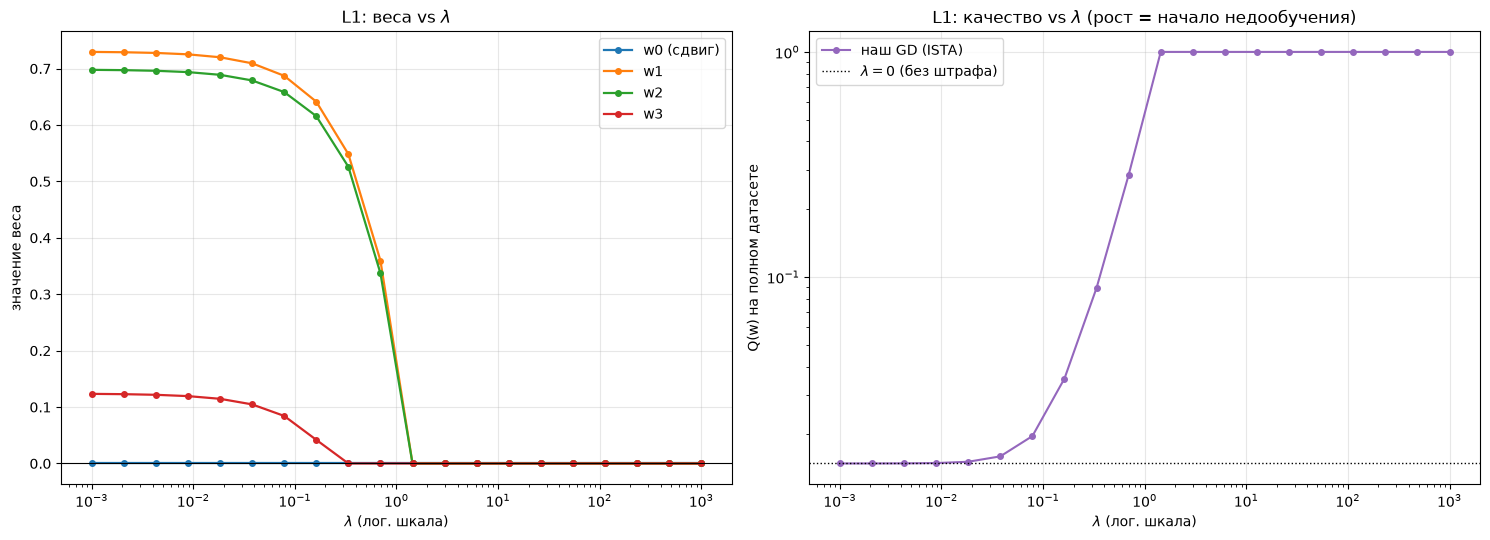

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

colors = ["C0", "C1", "C2", "C3"]

# --- слева: веса от lambda
for j in range(d):
    axes[0].plot(lambdas, W_l1[:, j], "o-", color=colors[j], ms=4, lw=1.6, label=weight_names[j])

axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xscale("log")
axes[0].set_xlabel(r"$\lambda$ (лог. шкала)")
axes[0].set_ylabel("значение веса")
axes[0].set_title("L1: веса vs $\\lambda$")
axes[0].legend()

# --- справа: качество от lambda
axes[1].plot(lambdas, Q_l1, "o-", ms=4, color="C4", label="наш GD (ISTA)")
axes[1].axhline(hist_gd[-1], color="k", ls=":", lw=1, label="$\\lambda = 0$ (без штрафа)")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel(r"$\lambda$ (лог. шкала)")
axes[1].set_ylabel("Q(w) на полном датасете")
axes[1].set_title("L1: качество vs $\\lambda$ (рост = начало недообучения)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Вывод по регуляризации

1. **Малые $\lambda$** ($\lesssim 0.01$) — штраф незаметен, веса совпадают с обычной регрессией
   ($\lambda = 0$), $Q$ минимально.
2. **Рост $\lambda$** — веса монотонно сжимаются к нулю, причём **неравномерно**: первыми
   обнуляются признаки со слабой связью с целью, дольше всех держится самый «сильный» вес.
   Именно это и есть автоматический отбор признаков.
3. **Большие $\lambda$** ($\gtrsim 3$) — все веса нулевые, модель вырождается в константу
   (среднее $y$); $Q$ упирается в дисперсию цели, то есть в $1$ для стандартизованной $y$.
   Это классическое **недообучение**: модель слишком «зажата», чтобы что-то предсказывать.


## 8. Что перенести в отчёт — чек-лист по пунктам задания

| Пункт задания | Где в ноутбуке | Что показать в отчёте |
|---|---|---|
| Датасет, ≥ 2 признака, ≥ 3 веса, масштабирование | разд. 1 | размеры `X`, что и зачем стандартизовано |
| Своя функция GD по алгоритму (веса, ε, цикл, критерий остановки) | разд. 2–3 | код + формула, сверка со sklearn |
| Эксперимент со скоростью обучения + вывод | разд. 4 | график $Q$ от итерации для нескольких $\eta$ |
| SGD: случайный объект на каждой итерации | разд. 5 | код, изменение одной строки внутри цикла |
| MSE обоих методов на одном графике + вывод о скорости | разд. 6 | график «MSE vs эпоха» |
| 20 коэффициентов регуляризации, веса от $\lambda$ | разд. 7 | график «веса vs $\lambda$», момент обнуления |
| L1 (чётный вариант) | разд. 7 | штраф $\lambda\sum|w_j|$, обнуление весов |

### Итоговые выводы (сформулируйте своими словами)

- Градиентный спуск — итеративный метод минимизации: шаг пропорционален градиенту,
  направление — против градиента; ответ не зависит от $\eta$, от неё зависит только скорость
  и сама возможность сходимости ($\eta$ выше порога $2/\lambda_{\max}$ — расходимость).
- Критерий $\|w^k - w^{k-1}\| < \varepsilon$ экономит итерации, но его обязательно дублируют
  ограничением `max_iter`: при неудачной $\eta$ (или в SGD, где шаг шумный) он может не сработать.
- SGD выигрывает по эпохам благодаря $n$-кратному числу шагов, но платит шумом: кривая MSE
  колеблется и не выходит на ровное плато.
- L1 не просто уменьшает веса, а **обнуляет** часть из них: это встроенный отбор признаков;
  слишком большой $\lambda$ превращает модель в константу.